# Phase 3: Model Training

Brief overview: reshaping game logs into leak-free pre-game rolling efficiency features, then training and comparing three models (scaled Logistic Regression baseline, Random Forest, XGBoost) to predict individual game outcomes without look-ahead bias.

## 1. Imports

In [1]:
from pathlib import Path
import joblib
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

## 2. Load Phase 2 Outputs

In [2]:
games_regular_season_grouped = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'team_season_features.csv')
games_combined = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'games_clean.csv', dtype={'GAME_ID': str})
games_regular_season = games_combined[games_combined['SEASON_TYPE_LABEL'] == 'Regular Season'].copy()
games_regular_season['WIN'] = games_regular_season['WL'].apply(lambda x: 1 if x == 'W' else 0)
display(games_regular_season_grouped.shape)
display(games_regular_season.shape)

(60, 15)

(4920, 31)

## 3. Build Game-Level Matchup & Per-Game Efficiency Table

**Question:** How do we pair each team with its opponent on every game 
and compute single-game Four Factors and Net Rating?

Each game contributes two rows (one from each team's perspective), 
giving us the raw per-game building blocks needed to compute strictly 
prior-game rolling averages in the next step.

In [3]:
games_model_base = games_regular_season.copy()

# building a small opponent side table (including OPP_PTS and OPP_DREB for ORB% and Net Rating)
games_model_opp = games_model_base[['GAME_ID', 'TEAM_ABBREVIATION', 'WIN', 'PTS', 'DREB']].rename(
    columns={
        'TEAM_ABBREVIATION': 'OPP_TEAM_ABBREVIATION',
        'WIN': 'OPP_WIN',
        'PTS': 'OPP_PTS',
        'DREB': 'OPP_DREB'
    }
)

# merging on GAME_ID to attach the opponent's stats to each row
games_model = pd.merge(
    games_model_base,
    games_model_opp,
    on='GAME_ID',
    how='left'
)

# dropping rows where a team matched w/ itself
games_model = games_model[games_model['TEAM_ABBREVIATION'] != games_model['OPP_TEAM_ABBREVIATION']].copy()

# computing single-game Four Factors and pace-adjusted Net Rating
games_model['GAME_eFG%'] = (games_model['FGM'] + 0.5 * games_model['FG3M']) / games_model['FGA']
games_model['GAME_TOV%'] = games_model['TOV'] / (games_model['FGA'] + 0.44 * games_model['FTA'] + games_model['TOV'])
games_model['GAME_ORB%'] = games_model['OREB'] / (games_model['OREB'] + games_model['OPP_DREB'])
games_model['GAME_FT Rate'] = games_model['FTM'] / games_model['FGA']
games_model['GAME_POSS'] = games_model['FGA'] - games_model['OREB'] + games_model['TOV'] + 0.44 * games_model['FTA']
games_model['GAME_NET_RATING'] = (games_model['PTS'] - games_model['OPP_PTS']) / games_model['GAME_POSS'] * 100

# previewing
display(games_model.shape)
display(games_model[['SEASON_LABEL', 'GAME_DATE', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN', 'GAME_NET_RATING']].head(10))

(4920, 41)

,SEASON_LABEL,GAME_DATE,GAME_ID,TEAM_ABBREVIATION,OPP_TEAM_ABBREVIATION,WIN,GAME_NET_RATING
1,2024-25,2025-04-13,0022401198,LAC,GSW,1,4.954419
3,2024-25,2025-04-13,0022401191,CHI,PHI,1,18.382353
5,2024-25,2025-04-13,0022401189,IND,CLE,1,6.265664
7,2024-25,2025-04-13,0022401200,SAC,PHX,1,12.178919
9,2024-25,2025-04-13,0022401194,MEM,DAL,1,34.113060
11,2024-25,2025-04-13,0022401193,HOU,DEN,0,-14.976038
13,2024-25,2025-04-13,0022401186,ORL,ATL,0,-12.422360
15,2024-25,2025-04-13,0022401188,NYK,BKN,1,8.126778
16,2024-25,2025-04-13,0022401186,ATL,ORL,1,12.195122
19,2024-25,2025-04-13,0022401195,MIN,UTA,1,10.886778


## 4. Compute Leak-Free Pre-Game Rolling Features

**Question:** How do we attach each team's season-to-date performance 
metrics prior to tip-off without leaking future results from later in 
the season?

Using full-season averages (or end-of-season `WIN_PERCENTAGE` and 
awards) to predict games inside that same season introduces in-season 
look-ahead leakage. Instead, we sort chronologically and compute an 
expanding mean over strictly prior games (`shift(1).expanding(min_periods=5)`), 
so Game $N$ only sees how both teams performed in Games $1 \dots N-1$.

In [4]:
# sorting chronologically within each season and team
games_model = games_model.sort_values(
    ['SEASON_LABEL', 'TEAM_ABBREVIATION', 'GAME_DATE', 'GAME_ID']
).reset_index(drop=True)

eff_cols = ['eFG%', 'TOV%', 'ORB%', 'FT Rate', 'NET_RATING']

# computing strictly pre-game expanding averages (requiring at least 5 prior games)
for col in eff_cols:
    games_model[col] = (
        games_model.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION'])[f'GAME_{col}']
        .transform(lambda s: s.shift(1).expanding(min_periods=5).mean())
    )

# building an OPP_ prefixed table of each opponent's pre-game rolling stats on that exact GAME_ID
opp_rolling = games_model[['GAME_ID', 'TEAM_ABBREVIATION'] + eff_cols].rename(
    columns={'TEAM_ABBREVIATION': 'OPP_TEAM_ABBREVIATION', **{c: f'OPP_{c}' for c in eff_cols}}
)

games_model = pd.merge(
    games_model,
    opp_rolling,
    on=['GAME_ID', 'OPP_TEAM_ABBREVIATION'],
    how='left'
)

display(games_model.shape)
display(games_model[['SEASON_LABEL', 'GAME_DATE', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION'] + eff_cols].tail(10))

(4920, 51)

,SEASON_LABEL,GAME_DATE,TEAM_ABBREVIATION,OPP_TEAM_ABBREVIATION,eFG%,TOV%,ORB%,FT Rate,NET_RATING
4910,2025-26,2026-03-27,WAS,GSW,0.535502,0.133462,0.242298,0.183783,-10.808623
4911,2025-26,2026-03-29,WAS,POR,0.536674,0.132998,0.240735,0.182419,-10.725543
4912,2025-26,2026-03-30,WAS,LAL,0.534780,0.133016,0.240070,0.182905,-11.041232
4913,2025-26,2026-04-01,WAS,PHI,0.534030,0.132343,0.238384,0.182186,-11.137511
4914,2025-26,2026-04-04,WAS,MIA,0.534953,0.131866,0.237671,0.181845,-11.260293
4915,2025-26,2026-04-05,WAS,BKN,0.535173,0.131084,0.238527,0.181811,-11.305463
4916,2025-26,2026-04-07,WAS,CHI,0.536182,0.131707,0.239386,0.182402,-11.237199
4917,2025-26,2026-04-09,WAS,CHI,0.535651,0.132327,0.238342,0.182006,-11.457488
4918,2025-26,2026-04-10,WAS,MIA,0.534554,0.132374,0.239673,0.182596,-11.445372
4919,2025-26,2026-04-12,WAS,CLE,0.535067,0.132184,0.238716,0.181818,-11.574089


## 5. Final Modeling Table

**Question:** What does our model-ready dataset look like once warm-up 
games (`< 5` prior games) are removed and trimmed to the 10 pre-game 
efficiency features?

In [5]:
# keeping only metadata + the 10 leak-free pre-game efficiency features
model_feature_cols = [
    'SEASON_LABEL', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN',
    'eFG%', 'TOV%', 'ORB%', 'FT Rate', 'NET_RATING',
    'OPP_eFG%', 'OPP_TOV%', 'OPP_ORB%', 'OPP_FT Rate', 'OPP_NET_RATING'
]

# dropping early-season warm-up games where either team has fewer than 5 prior games
games_model_final = games_model[model_feature_cols].dropna().reset_index(drop=True)

print(f"Final leak-free modeling table shape: {games_model_final.shape}")
print("Null values in each column:")
display(games_model_final.isnull().sum())


Final leak-free modeling table shape: (4606, 15)
Null values in each column:


SEASON_LABEL             0
GAME_ID                  0
TEAM_ABBREVIATION        0
OPP_TEAM_ABBREVIATION    0
WIN                      0
eFG%                     0
TOV%                     0
ORB%                     0
FT Rate                  0
NET_RATING               0
OPP_eFG%                 0
OPP_TOV%                 0
OPP_ORB%                 0
OPP_FT Rate              0
OPP_NET_RATING           0
dtype: int64

**Takeaway:** After dropping the 314 early-season warm-up rows where either team had fewer than 5 prior games, the leak-free modeling table retains 4,606 rows (2,304 in 2024-25 and 2,302 in 2025-26) with zero missing values across all 10 pre-game rolling efficiency features.

## 6. Train/Test Split

**Question:** How do we split this data so the model is evaluated on 
data it hasn't seen, without leaking information across seasons?

We split by season rather than randomly — training on 2024-25 and 
testing on 2025-26 — since a random row-level split could let games 
from the same season leak similar team-strength signals between train 
and test sets.

In [6]:
# training on 24-25, testing on 25-26
train_data = games_model_final[games_model_final['SEASON_LABEL'] == '2024-25']
test_data = games_model_final[games_model_final['SEASON_LABEL'] == '2025-26']

# separating features from the target variable
drop_cols = ['SEASON_LABEL', 'GAME_ID', 'TEAM_ABBREVIATION', 'OPP_TEAM_ABBREVIATION', 'WIN']

X_train = train_data.drop(columns=drop_cols)
y_train = train_data['WIN']

X_test = test_data.drop(columns=drop_cols)
y_test = test_data['WIN']

display(X_train.shape)
display(X_test.shape)
display(y_train.shape)
display(y_test.shape)

(2304, 10)

(2302, 10)

(2304,)

(2302,)

## 7. Standardized Logistic Regression Baseline

**Question:** How well does a standardized linear model predict game outcomes strictly from pre-game rolling efficiency features, before trying non-linear tree ensembles?

In [7]:
import matplotlib.pyplot as plt

# training a standardized logistic regression pipeline (fit scaler strictly on X_train)
log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression(max_iter=1000))
])
log_reg.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
log_reg_preds = log_reg.predict(X_test)
log_reg_probs = log_reg.predict_proba(X_test)[:, 1]

# evaluating the model's performance
log_reg_accuracy = accuracy_score(y_test, log_reg_preds)
log_reg_auc = roc_auc_score(y_test, log_reg_probs)
log_reg_cm = confusion_matrix(y_test, log_reg_preds)

print(f"Logistic Regression Accuracy: {log_reg_accuracy:.4f}")
print(f"Logistic Regression AUC-ROC:  {log_reg_auc:.4f}")
print("Confusion Matrix:")
print(log_reg_cm)


Logistic Regression Accuracy: 0.6699
Logistic Regression AUC-ROC:  0.7324
Confusion Matrix:
[[771 380]
 [380 771]]


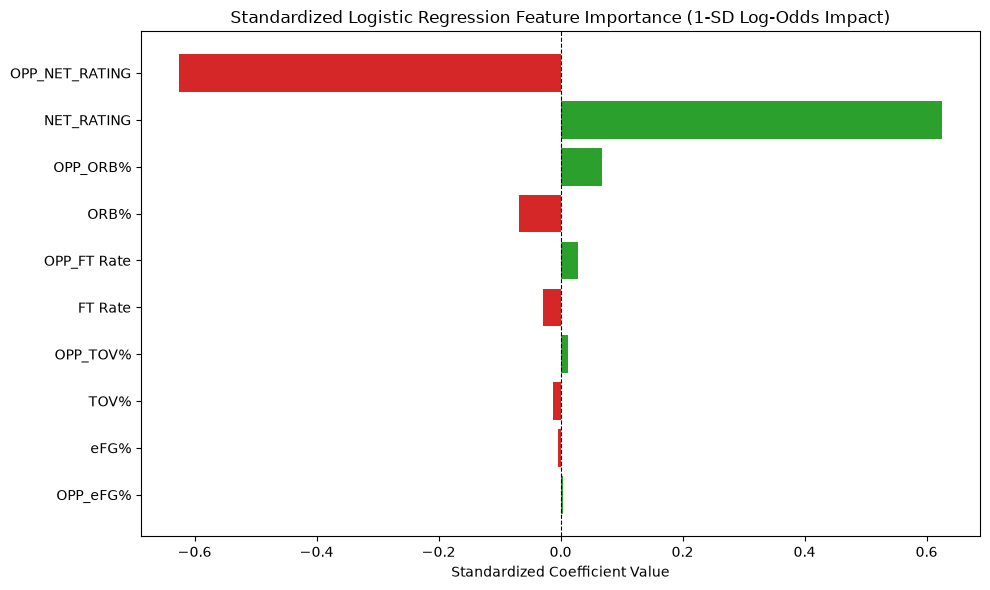

In [8]:
# Feature Importance (Standardized Logistic Regression Coefficients — 1 SD Impact)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_names = X_train.columns
coefs = log_reg.named_steps['log_reg'].coef_[0]

fi_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
fi_df = fi_df.sort_values('Coefficient', key=abs, ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(
    fi_df['Feature'],
    fi_df['Coefficient'],
    color=np.where(fi_df['Coefficient'] > 0, '#2ca02c', '#d62728')
)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Standardized Logistic Regression Feature Importance (1-SD Log-Odds Impact)')
plt.xlabel('Standardized Coefficient Value')
plt.tight_layout()
plt.show()

**Takeaway:** With look-ahead leakage removed, the standardized Logistic Regression pipeline achieves **67.0% accuracy** (`0.6699`) and **0.7324 AUC-ROC** on the held-out 2025-26 season (and **64.9% accuracy / 0.7156 AUC-ROC** when reversing the chronological split below). Putting all features on a 1-SD scale reveals that pre-game `NET_RATING` and `OPP_NET_RATING` carry the largest log-odds weights (`±0.63`), since pace-adjusted net rating already synthesizes offensive and defensive efficiency. The confusion matrix (`[[771, 380], [380, 771]]`) is symmetric by design because each game appears from both teams' perspectives.

### 7b. Stability Check: Reverse Train/Test Split
To ensure our model isn't just getting lucky on the 2025-26 season, let's reverse the split: train on 25-26, test on 24-25.

In [9]:
X_train_rev = test_data.drop(columns=drop_cols)
y_train_rev = test_data['WIN']
X_test_rev = train_data.drop(columns=drop_cols)
y_test_rev = train_data['WIN']

log_reg_rev = Pipeline([
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression(max_iter=1000))
])
log_reg_rev.fit(X_train_rev, y_train_rev)
rev_preds = log_reg_rev.predict(X_test_rev)
rev_probs = log_reg_rev.predict_proba(X_test_rev)[:, 1]
rev_accuracy = accuracy_score(y_test_rev, rev_preds)
rev_auc = roc_auc_score(y_test_rev, rev_probs)
print(f"Reverse Split Accuracy (Train 25-26, Test 24-25): {rev_accuracy:.4f}")
print(f"Reverse Split AUC-ROC  (Train 25-26, Test 24-25): {rev_auc:.4f}")

Reverse Split Accuracy (Train 25-26, Test 24-25): 0.6493
Reverse Split AUC-ROC  (Train 25-26, Test 24-25): 0.7156


## 8. Random Forest

**Question:** Does a non-linear model that can capture feature 
interactions outperform the linear baseline?

In [10]:
# training a rf classifier model
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42
)
rf.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
rf_preds = rf.predict(X_test)
rf_probs = rf.predict_proba(X_test)[:, 1]

# evaluating the model's performance
rf_accuracy = accuracy_score(y_test, rf_preds)
rf_auc = roc_auc_score(y_test, rf_probs)
rf_cm = confusion_matrix(y_test, rf_preds)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest AUC-ROC:  {rf_auc:.4f}")
print("Confusion Matrix:")
print(rf_cm)

Random Forest Accuracy: 0.6642
Random Forest AUC-ROC:  0.7251
Confusion Matrix:
[[779 372]
 [401 750]]


**Takeaway:** Random Forest achieves **66.4% accuracy** (`0.6642`) and **0.7251 AUC-ROC** — slightly below the standardized Logistic Regression baseline (`67.0%` / `0.7324`). This indicates that pre-game NBA team efficiency differentials combine in a predominantly linear, additive fashion rather than relying on high-order feature interactions.

## 9. XGBoost

**Question:** Does gradient boosting, which builds trees sequentially 
to correct prior errors, perform differently than Random Forest's 
independent-tree approach?

In [11]:
# training an xgboost classifier model
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

# predicting on the held-out 2025-26 season
xgb_preds = xgb.predict(X_test)
xgb_probs = xgb.predict_proba(X_test)[:, 1]

# evaluating the model's performance
xgb_accuracy = accuracy_score(y_test, xgb_preds)
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_cm = confusion_matrix(y_test, xgb_preds)

print(f"XGBoost Accuracy: {xgb_accuracy:.4f}")
print(f"XGBoost AUC-ROC:  {xgb_auc:.4f}")
print("Confusion Matrix:")
print(xgb_cm)

XGBoost Accuracy: 0.6260
XGBoost AUC-ROC:  0.6731
Confusion Matrix:
[[703 448]
 [413 738]]


**Takeaway:** XGBoost achieves **62.6% accuracy** (`0.6260`) and **0.6731 AUC-ROC**, the lowest of the three candidates. Sequential boosted trees overfit noisy early- and mid-season rolling fluctuations on a single training season (`2,304` rows), reinforcing that regularized linear log-odds generalize best out-of-sample.

## 10. Model Comparison

**Question:** Across all three models, which performs best, and what 
does that tell us?

In [12]:
# building a comparison table across all 3 models
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [log_reg_accuracy, rf_accuracy, xgb_accuracy],
    'ROC_AUC': [log_reg_auc, rf_auc, xgb_auc]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

display(model_comparison)

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.669852,0.732446
1,Random Forest,0.664205,0.725085
2,XGBoost,0.625977,0.673054


**Takeaway:** Across all three leak-free models, **standardized Logistic Regression** leads in both **Accuracy (67.0%)** and **ROC-AUC (0.7324)**, outperforming Random Forest (`66.4%`, `0.7251`) and XGBoost (`62.6%`, `0.6731`). Eliminating circular `WIN_PERCENTAGE` and end-of-season look-ahead bias yields an honest, realistic out-of-sample NBA game predictor whose calibrated probability pipeline (`StandardScaler` + `LogisticRegression`) carries directly into Phase 4's Monte Carlo season simulation.

In [13]:
# saving model comparison & calibrated pipeline
model_comparison.to_csv(PROJECT_ROOT / 'outputs' / 'model_comparison.csv', index=False)
_ = joblib.dump(log_reg, PROJECT_ROOT / 'models' / 'logistic_regression_model.pkl')
print('Saved model comparison and calibrated pipeline to outputs/ and models/.')

Saved model comparison and calibrated pipeline to outputs/ and models/.
